# SpaceRec C2 xDBiT workflow with OpenPhenom

This notebook follows the same public API sequence as `spacerec.ipynb`. It reuses the supplied C2 deconvolution and routes every cerebellum call to the validated workflow that produced `resources/cerebellum`; no approximate or alternate implementation is used.

| Step | API | Output |
| --- | --- | --- |
| 1 | `spacerec.rctd_ref(...)` | platform-normalized `mu_ref` and gene list |
| 2 | `spacerec.ge(...)`, `spacerec.mask(...)` | OpenPhenom embedding and filtered tissue grids |
| 3.1 | `spacerec.stage1(...)` | router checkpoint and grid types |
| 3.2 | `spacerec.stage2(...)` | expression checkpoint and grid predictions |
| 4 | display | requested C2 window images |

In [1]:
from __future__ import annotations

import json
import sys
from pathlib import Path
from pprint import pprint

import anndata as ad
import numpy as np
import pandas as pd


def find_spacerec_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for path in (start, *start.parents):
        if (path / 'spacerec' / 'api.py').is_file():
            return path
    raise FileNotFoundError('Could not find the repository root containing spacerec/api.py')


def require_files(*paths: Path) -> None:
    missing = [str(path) for path in paths if not path.is_file() or path.stat().st_size == 0]
    if missing:
        raise FileNotFoundError('Missing required files:\n' + '\n'.join(missing))


ROOT = find_spacerec_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import spacerec.api as spacerec

dataset = 'cerebellum'
sample_id = 'C2'
resource_root = ROOT / 'resources' / dataset
sample_root = resource_root / sample_id
deconv_csv = sample_root / 'deconv' / 'deconv.csv'
stage1_st_h5ad = sample_root / 'dbit' / 'st_stage1.h5ad'
stage1_gene_list = sample_root / 'reference' / 'stage1_placeholder_genes.txt'
fullres_image = sample_root / 'image' / 'fullres_4ch.ome.tif'
spot_positions = sample_root / 'dbit' / 'tissue_positions.csv'
require_files(deconv_csv, stage1_st_h5ad, stage1_gene_list, fullres_image, spot_positions)

pprint({'root': ROOT, 'dataset': dataset, 'sample': sample_id, 'resources_and_outputs': sample_root})

{'dataset': 'cerebellum',
 'resources_and_outputs': PosixPath('/ocean/projects/bio260060p/gwang17/SpaceRec_project/SpaceRec/resources/cerebellum/C2'),
 'root': PosixPath('/ocean/projects/bio260060p/gwang17/SpaceRec_project/SpaceRec'),
 'sample': 'C2'}


## Step 1: supplied deconvolution and expression reference

Validate and reuse the supplied eight-class deconvolution, then build the platform-normalized reference through the same cerebellum workflow used by `resources/cerebellum`.

In [2]:
adata = ad.read_h5ad(stage1_st_h5ad, backed='r')
spot_ids = adata.obs_names.astype(str).tolist()
adata.file.close()
deconv = pd.read_csv(deconv_csv, index_col=0)
values = deconv.to_numpy(dtype=np.float64)
if deconv.index.astype(str).tolist() != spot_ids:
    raise ValueError('Deconvolution rows do not match the C2 xDBiT spot order.')
if not np.isfinite(values).all() or np.any(values < 0) or not np.allclose(values.sum(1), 1.0, atol=1e-6):
    raise ValueError('Deconvolution proportions are invalid.')

reference_summary = spacerec.rctd_ref(
    dataset=dataset,
    sample_id=sample_id,
    deconv_csv=deconv_csv,
    stage1_st_h5ad=stage1_st_h5ad,
    stage1_gene_list=stage1_gene_list,
    force=True,
)
gene_list = Path(reference_summary['gene_list'])
mu_ref = Path(reference_summary['mu_ref'])
stage2_st_h5ad = Path(reference_summary['st_h5ad'])
require_files(gene_list, mu_ref, stage2_st_h5ad)
pprint(reference_summary)

{'cell_type_order': '/ocean/projects/bio260060p/gwang17/SpaceRec_project/resources/cerebellum/C2/reference/cell_type_order.txt',
 'gene_list': '/ocean/projects/bio260060p/gwang17/SpaceRec_project/resources/cerebellum/C2/reference/genes.txt',
 'hvg_method': 'scanpy highly_variable_genes flavor=seurat after spatial '
               'normalize_total(1e4) and log1p',
 'hvg_selection': 'section-specific, restricted to genes retained by the '
                  'dedicated RCTD platform-normalized reference',
 'input_profile_csv': '/ocean/projects/bio260060p/gwang17/SpaceRec_project/resources/handoff_cerebellum/spacerec_v2_openphenom_mean_30px/C2/stage2/reference/atlas_cluster_equalweight_merged8_profiles.csv',
 'mu_ref': '/ocean/projects/bio260060p/gwang17/SpaceRec_project/resources/cerebellum/C2/reference/mu_ref.npy',
 'mu_ref_row_sum_max': 1.0,
 'mu_ref_row_sum_min': 0.9999999403953552,
 'mu_ref_shape': [8, 8000],
 'n_hvg': 8000,
 'n_platform_reference_genes': 13537,
 'n_spatial_genes': 261

## Step 2: OpenPhenom grid embedding and SpaceRec mask

DAPI, phalloidin, and CD31 are fused by channel mean. Local and global 384-dimensional representations are concatenated into each 768-dimensional grid embedding.

In [3]:
ge_summary = spacerec.ge(
    dataset=dataset,
    sample_id=sample_id,
    model='openphenom',
    he_image=fullres_image,
    positions_csv=spot_positions,
    output_dir=sample_root / 'embedding',
    patch_size=480,
    stride=120,
    batch_size=16,
    force=True,
    enable_progress_bar=True,
)
bbox_embedding = Path(ge_summary['output_h5'])
require_files(bbox_embedding)
pprint(ge_summary)

OpenPhenom C2:   0%|          | 0/14762 [00:00<?, ?patch/s]

{'channel_order': ['dapi', 'phalloidin', 'CD31'],
 'elapsed_seconds': 108.17873358726501,
 'feature_key': 'openphenom_channelmean_local_global_768',
 'feature_max': 14.057044982910156,
 'feature_min': -9.40383529663086,
 'feature_rule': 'local mean(3x384) + global mean(3x384), then local/global '
                 'concat = 768',
 'feature_shape': [220896, 768],
 'feature_std': 0.4373471140861511,
 'gpu': 'Tesla V100-SXM2-32GB',
 'grid_bbox_xyxy': [4260, 3150, 18420, 17190],
 'grids_per_spot_max': 49,
 'grids_per_spot_median': 42.0,
 'grids_per_spot_min': 36,
 'image_mask_used': False,
 'n_grids': 220896,
 'n_inference_only_grids': 183811,
 'n_patches': 14762,
 'n_spots': 853,
 'n_supervised_grids': 37085,
 'output_h5': '/ocean/projects/bio260060p/gwang17/SpaceRec_project/resources/cerebellum/C2/embedding/grid_embedding.h5',
 'peak_cuda_memory_bytes': 1137868800,
 'sample': 'C2',
 'selection': 'tissue-bbox',
 'selection_rule': 'continuous 30 px grid over axis-aligned bbox of all '
     

In [4]:
mask_summary = spacerec.mask(
    dataset=dataset,
    sample_id=sample_id,
    grid_embedding_h5=bbox_embedding,
    output_dir=sample_root / 'mask',
    force=True,
)
training_embedding = Path(mask_summary['training_h5'])
require_files(training_embedding, Path(mask_summary['mask_h5']))
pprint(mask_summary)

{'hole_overlay': '/ocean/projects/bio260060p/gwang17/SpaceRec_project/resources/handoff_cerebellum/spacerec_v2_openphenom_mean_30px/C2/mask/internal_holes_ge4_overlay_reference.png',
 'largest_hole_grids': 628,
 'mask_h5': '/ocean/projects/bio260060p/gwang17/SpaceRec_project/resources/cerebellum/C2/mask/he_mask_grid.h5',
 'mask_summary': '/ocean/projects/bio260060p/gwang17/SpaceRec_project/resources/cerebellum/C2/mask/mask_summary.json',
 'n_background_or_hole': 64564,
 'n_grids': 220896,
 'n_holes_ge_16_grids': 38,
 'n_holes_ge_4_grids': 62,
 'n_internal_hole_grids': 3888,
 'n_internal_holes': 75,
 'n_supervised_grids_retained': 36253,
 'n_supervised_spots_with_no_retained_grid': 1,
 'n_tissue_final': 156332,
 'pipeline_step': 'SpaceRec mask before Stage 1 training',
 'reference_full_size_wh': [20296, 20296],
 'reference_image': '/ocean/projects/bio260060p/gwang17/SpaceRec_project/resources/handoff_cerebellum/spacerec_v2_openphenom_mean_30px/C2/mask/pseudo_he_inverted_3ch_lowres.png',

## Step 3.1: Stage 1 router and grid type model

In [5]:
stage1_summary = spacerec.stage1(
    dataset=dataset,
    sample_id=sample_id,
    st_h5ad=stage1_st_h5ad,
    deconv_csv=deconv_csv,
    grid_embedding_h5=training_embedding,
    gene_list=stage1_gene_list,
    run_dir=sample_root / 'model_pred' / 'train',
    projection_dim=1024,
    stage1_epochs=70,
    batch_size=8,
    skip_input_projector=False,
    factorized_head_hidden_layers=1,
    scale_head_hidden_dim=256,
    delta_head_hidden_dim=256,
    enable_progress_bar=True,
    force=True,
)
stage1_checkpoint = Path(stage1_summary['checkpoint'])
require_files(stage1_checkpoint, Path(stage1_summary['grid_type_csv']))
pprint(stage1_summary)

Stage 1 C2:   0%|          | 0/70 [00:00<?, ?epoch/s]

{'cell_type_order': ['other_neurons',
                     'excitatory_neurons',
                     'inhibitory_neurons',
                     'astroglia',
                     'oligodendroglia',
                     'immune',
                     'vascular_stromal',
                     'ventricular_epithelium'],
 'checkpoint': '/ocean/projects/bio260060p/gwang17/SpaceRec_project/resources/cerebellum/C2/model_pred/stage1_checkpoint.ckpt',
 'grid_type_csv': '/ocean/projects/bio260060p/gwang17/SpaceRec_project/resources/cerebellum/C2/model_pred/stage1_grid_type.csv',
 'mu_ref': None,
 'n_cell_types': 8,
 'n_grids': 156332,
 'n_mask_excluded_spots': 1,
 'n_spots': 853,
 'n_supervised_spots': 852,
 'probability_row_sum_max': 1.0000001998868,
 'probability_row_sum_min': 0.99999978327,
 'sample': 'C2',
 'spot_fit': {'mean_absolute_error': 0.0147018337899732,
              'mean_spot_l1': 0.1176146703197856,
              'n_spots_with_grids': 852,
              'n_spots_without_grids': 1,

## Step 3.2: Stage 2 finetune-mu expression model

The validated workflow adapts the Stage 1 checkpoint to the real gene dimension, preserves the trained projector/router, trains the expression heads, and validates the complete grid export.

In [7]:
stage2_summary = spacerec.stage2(
    dataset=dataset,
    sample_id=sample_id,
    st_h5ad=stage2_st_h5ad,
    deconv_csv=deconv_csv,
    grid_embedding_h5=training_embedding,
    stage1_checkpoint=stage1_checkpoint,
    gene_txt=gene_list,
    mu_ref=mu_ref,
    run_dir=sample_root / 'model_pred' / 'train',
    projection_dim=1024,
    stage2_epochs=70,
    batch_size=4,
    skip_input_projector=False,
    factorized_head_hidden_layers=1,
    scale_head_hidden_dim=256,
    delta_head_hidden_dim=256,
    agg=False,
    enable_progress_bar=True,
    force=True,
)
require_files(Path(stage2_summary['stage2_checkpoint']), Path(stage2_summary['grid_predictions_h5']))
pprint(stage2_summary)

{'all_expression_finite_nonnegative': True,
 'cell_type_order': ['other_neurons',
                     'excitatory_neurons',
                     'inhibitory_neurons',
                     'astroglia',
                     'oligodendroglia',
                     'immune',
                     'vascular_stromal',
                     'ventricular_epithelium'],
 'cell_type_order_matches_stage1': True,
 'cuda_recorded_by_training': True,
 'expression_max': 29.06018829345703,
 'expression_min': 5.007618086881286e-17,
 'expression_shape': [156332, 8000],
 'frozen_router_max_abs_difference_from_stage1': 3.4570693969726562e-06,
 'gene_expression_metrics_csv': '/ocean/projects/bio260060p/gwang17/SpaceRec_project/resources/handoff_cerebellum/spacerec_v2_openphenom_mean_30px/C2/stage2/training/metrics/gene_expression_metrics.csv',
 'gene_order_matches_reference_and_h5ad': True,
 'geometry_exactly_matches_filtered_embedding': True,
 'grid_predictions_h5': '/ocean/projects/bio260060p/gwang17/Space

## Step 4: requested C2 window visualization

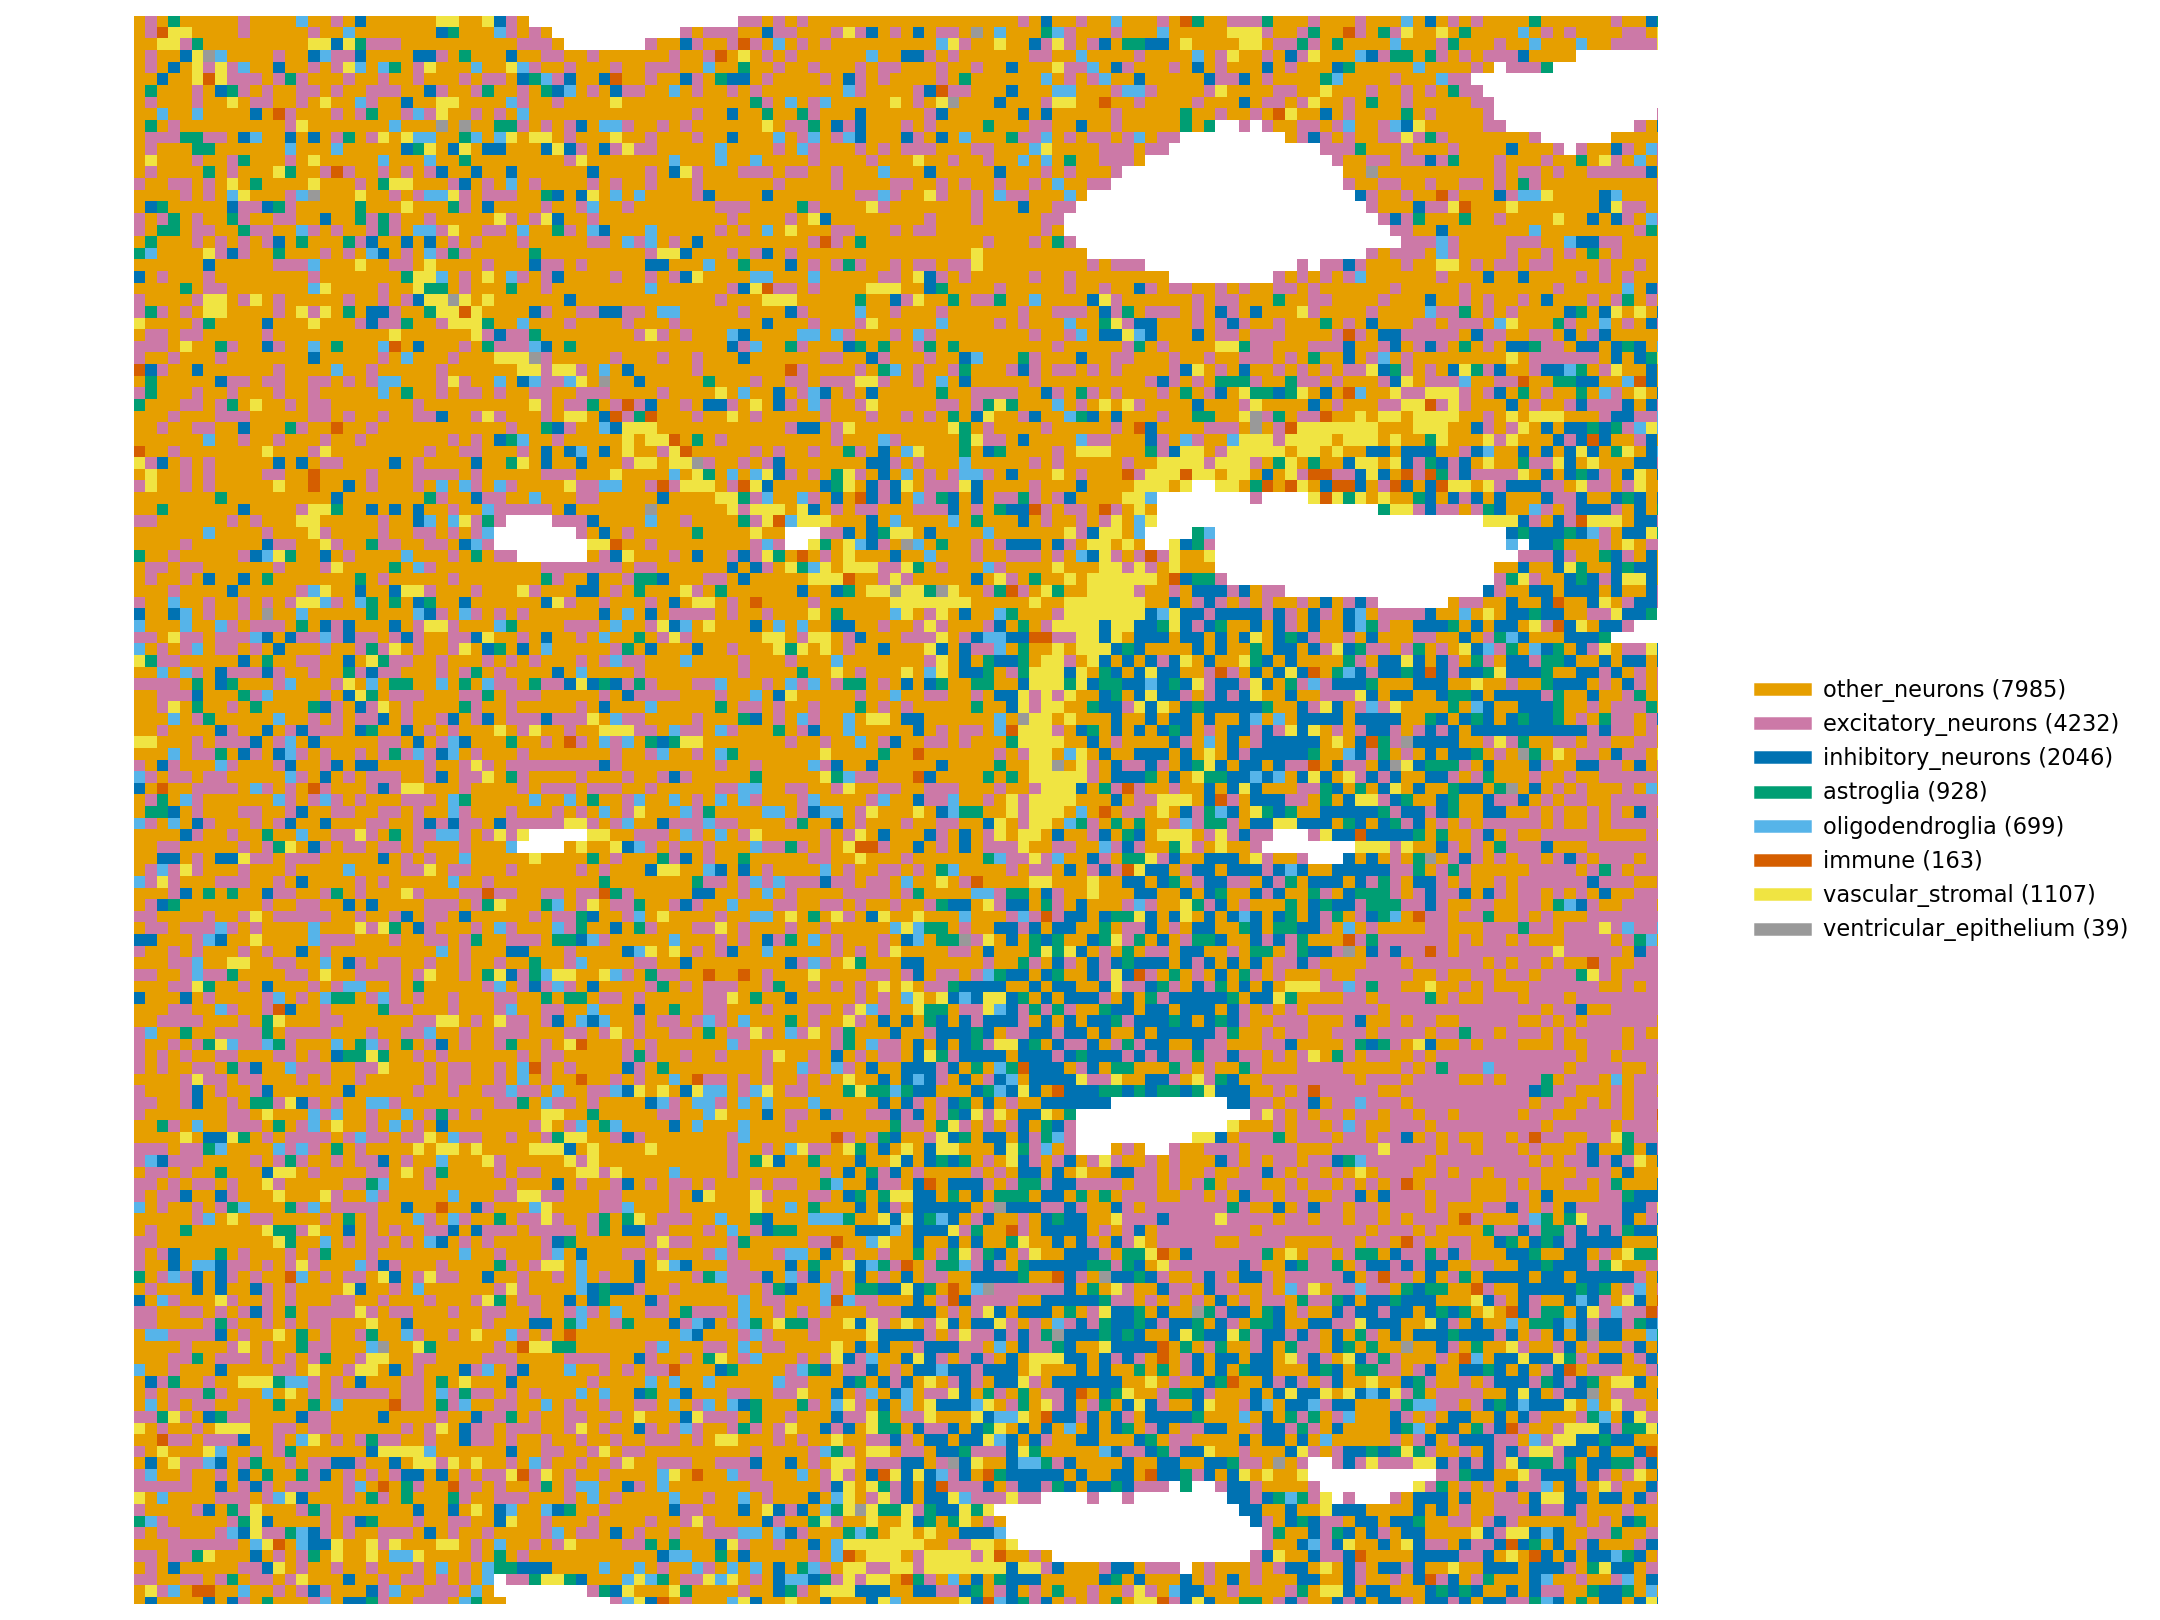

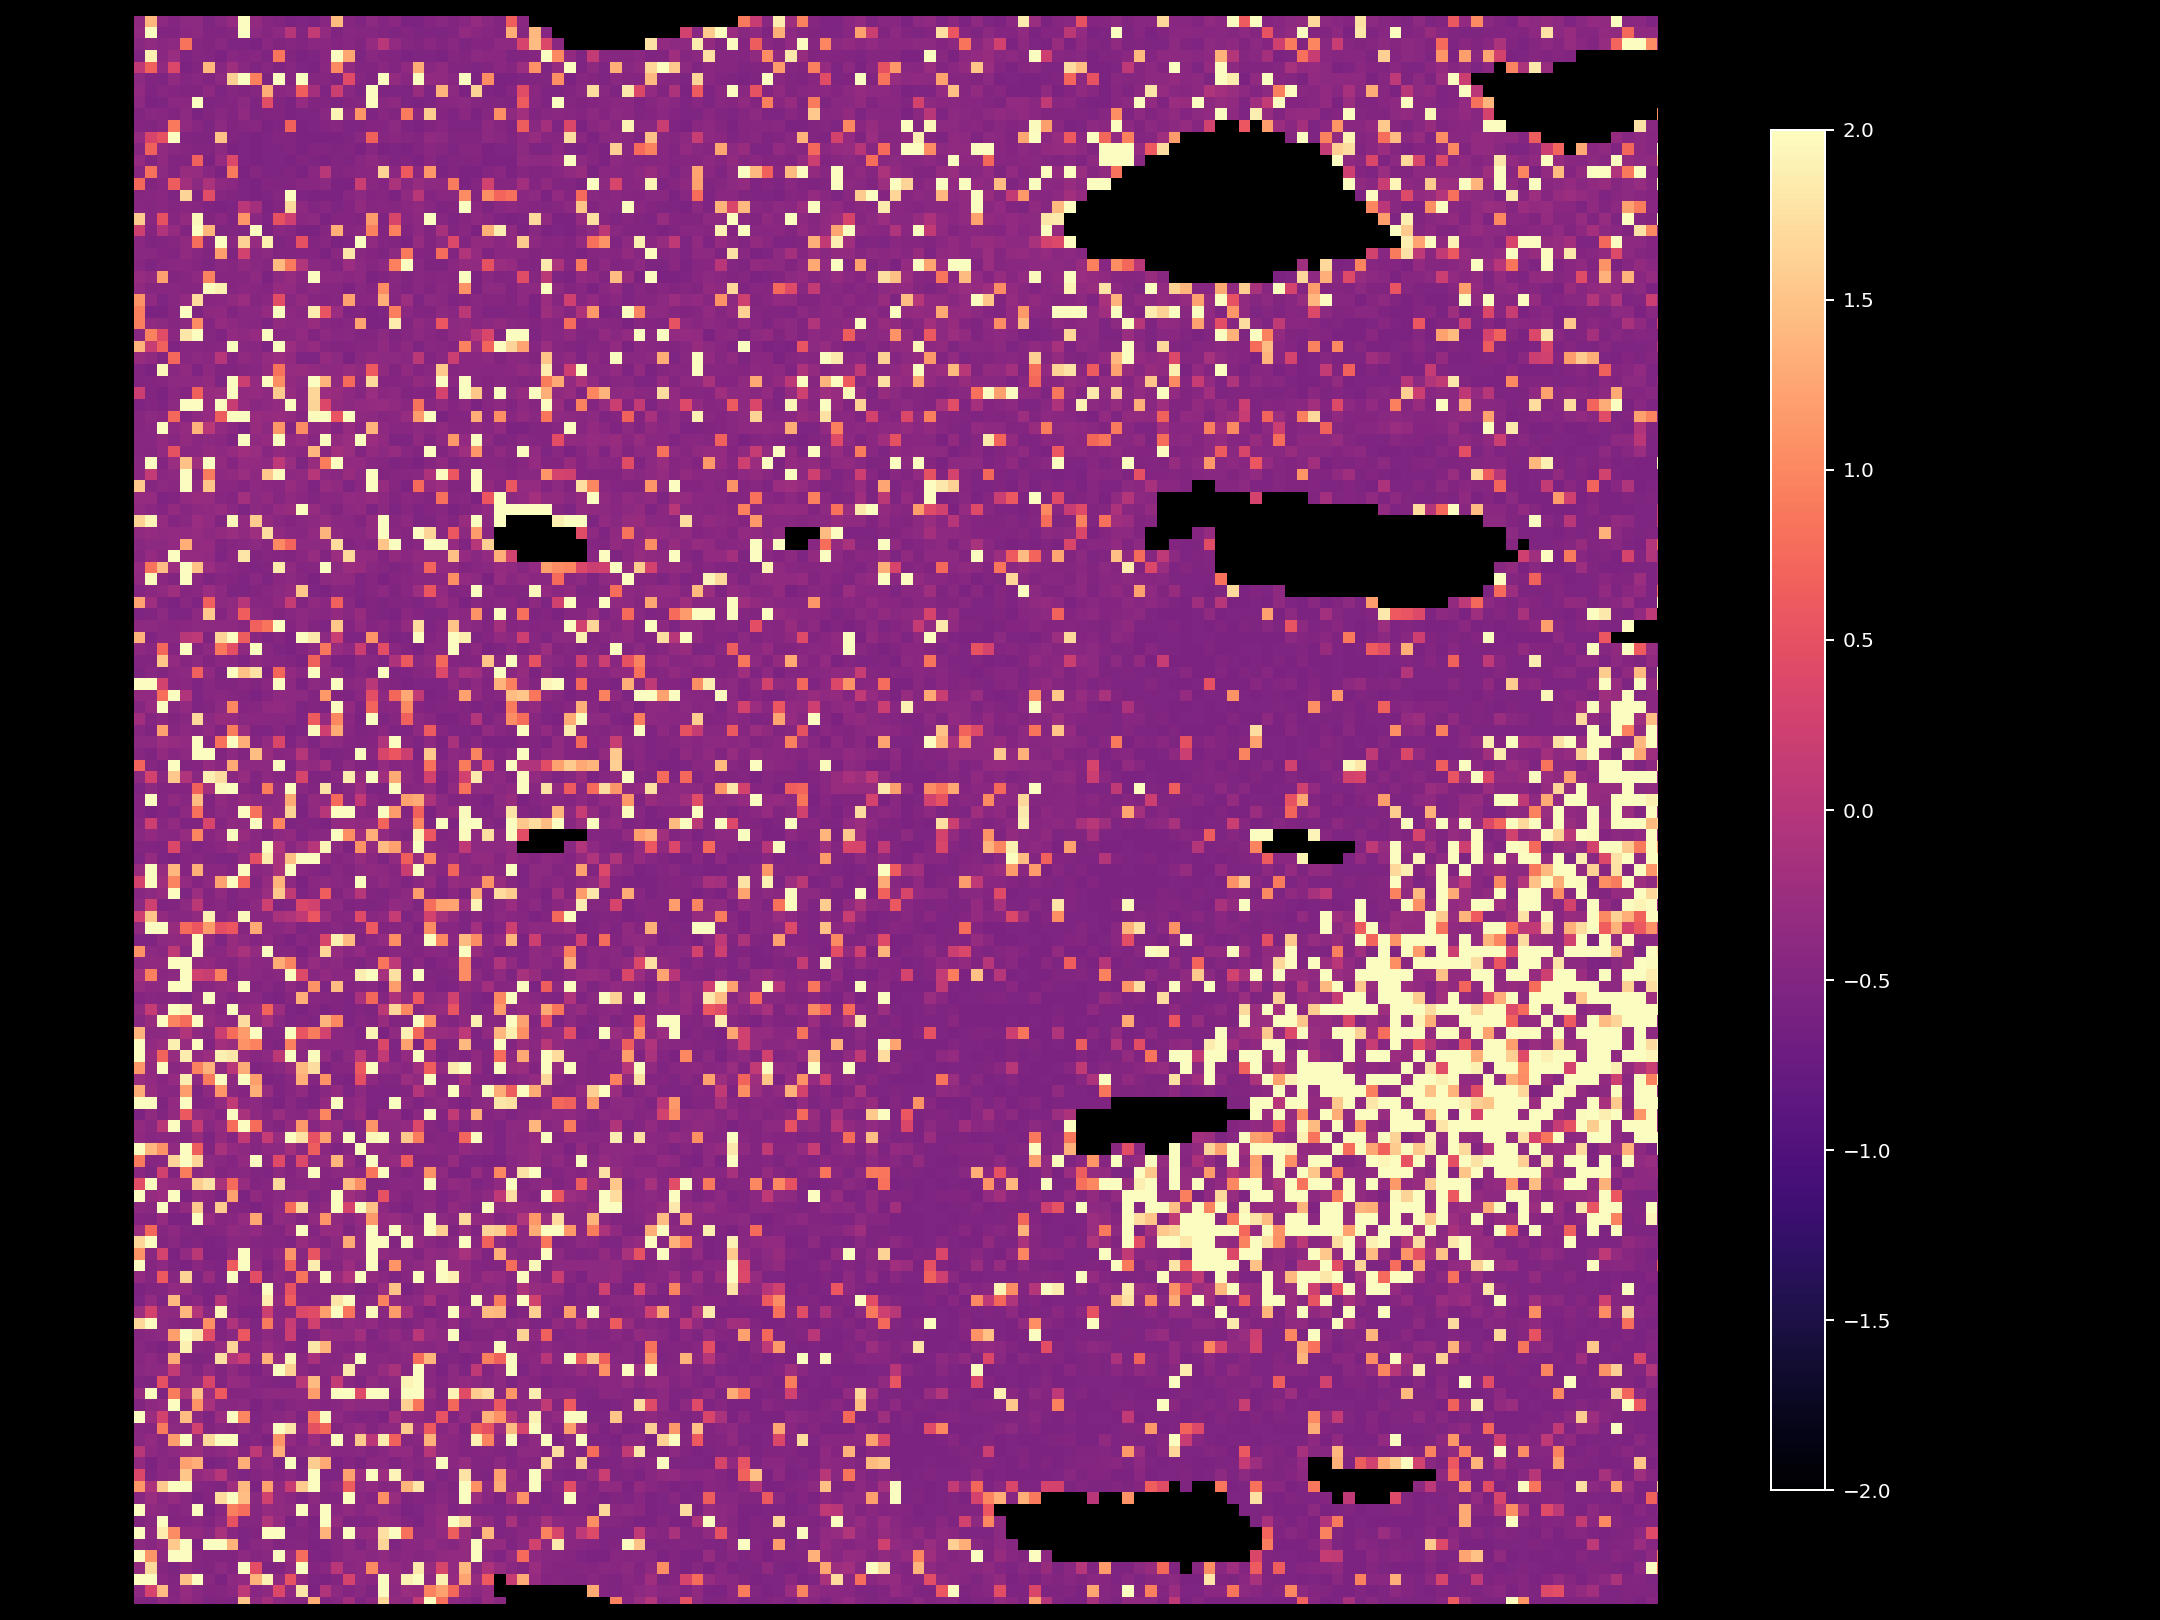

In [8]:
import importlib

from IPython.display import Image, display
import spacerec.evaluation as evaluation
import spacerec.evaluation.plot as evaluation_plot

importlib.reload(evaluation_plot)
importlib.reload(evaluation)

bbox_xyxy = (4096, 8192, 8192, 12288)
window_dir = sample_root / 'model_pred' / 'train' / 'metrics' / 'windows' / 'window_4096_8192_8192_12288'
type_plot = spacerec.plottype(
    dataset=dataset,
    grid_type_csv=Path(stage1_summary['grid_type_csv']),
    window=bbox_xyxy,
    output_dir=window_dir,
    output_name='predicted_type.png',
)
expr_plot = spacerec.plotexpr(
    dataset=dataset,
    grid_predictions_h5=Path(stage2_summary['grid_predictions_h5']),
    window=bbox_xyxy,
    output_dir=window_dir,
    gene='Slc17a7',
    output_name='Excitatory_neurons_Slc17a7_grid_expr.png',
)
predicted_type_png = Path(type_plot['grid_type_png'])
slc17a7_png = Path(expr_plot['grid_expr_png'])
require_files(predicted_type_png, slc17a7_png)
display(Image(filename=str(predicted_type_png)))
display(Image(filename=str(slc17a7_png)))